observation_index
0      318.040
1      333.334
2      327.566
3      353.635
4      357.113
        ...   
286    510.025
287    328.441
288    375.494
289    406.937
290    512.087
Name: range, Length: 291, dtype: float64
0          0
1          1
2          2
3          3
4          4
        ... 
71872    242
71873    243
71874    244
71875    245
71876    246
Name: beam_index, Length: 71877, dtype: int64
0       1787659624306703584
1       1787659624307014656
2       1787659624311068128
3       1787659624355890592
4       1787659624359265088
               ...         
1144    1787659652896830848
1145    1787659652996882656
1146    1787659653111300992
1147    1787659653229253344
1148    1787659653242587104
Name: Timestamp, Length: 1149, dtype: int64
0       9.92
1       9.96
2       9.96
3       9.95
4       9.91
        ... 
1144    5.02
1145   -4.10
1146    7.06
1147    4.88
1148    2.31
Name: az, Length: 1149, dtype: float64
0.0
0       0.000000
1       0.009604
2       0.01593

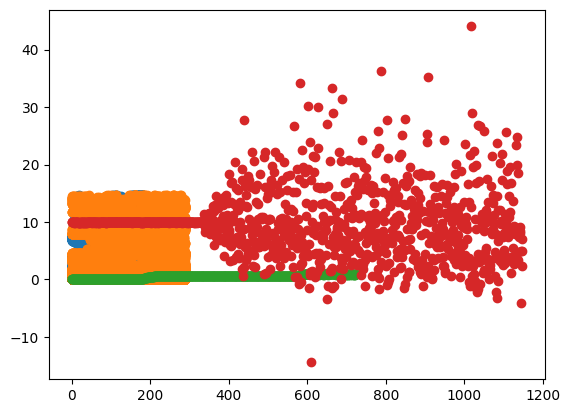

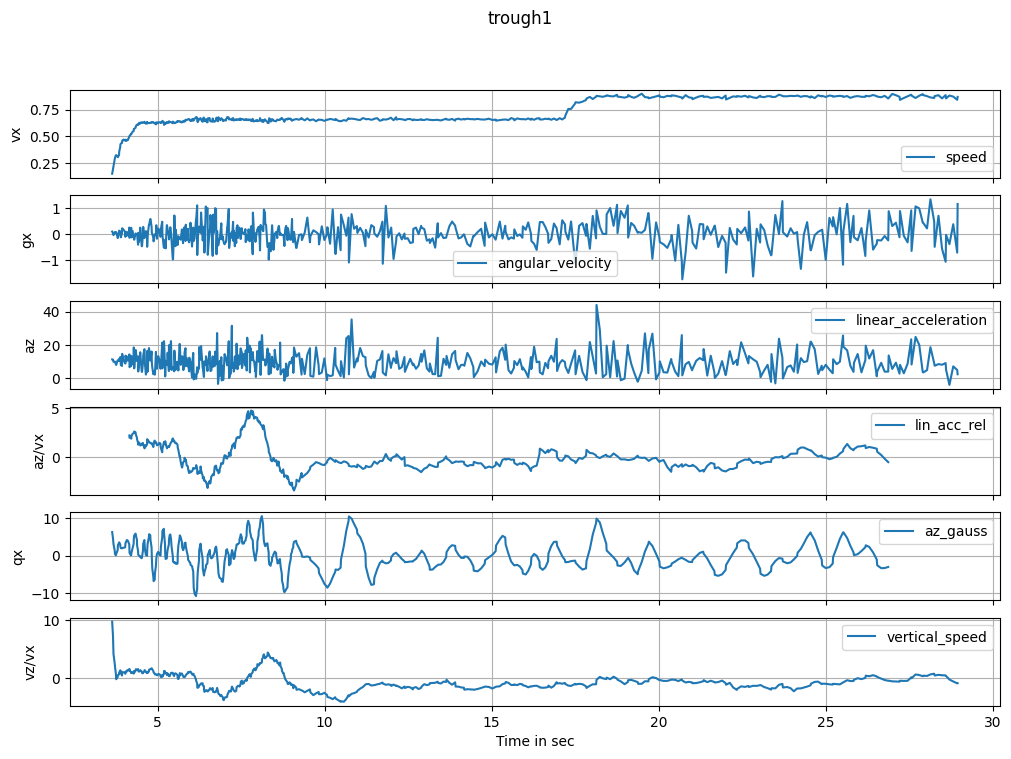

np.float64(0.010381810901161848)

In [79]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statistics

desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\ASA_LIMO_data\my_all_sensor_data_test19"

lidar_dir = os.path.join(desktop_path,"extracted_lidar", "lidar_data_v2.csv")
imu_dir = os.path.join(desktop_path,"extracted_imu", "imu_data_v3.csv")
odom_dir = os.path.join(desktop_path,"extracted_odom", "odom_data_v3.csv")

lidar_data = pd.read_csv(lidar_dir)
imu_data = pd.read_csv(imu_dir)
odom_data = pd.read_csv(odom_dir)

grouped = lidar_data.groupby("observation_index")["range"].sum()
print(grouped)
print(lidar_data["beam_index"])
print(imu_data["Timestamp"])
print(imu_data["az"])
plt.scatter(lidar_data["beam_index"], lidar_data["range"])
plt.scatter(lidar_data["observation_index"], lidar_data["range"])
plt.scatter(odom_data["index"], odom_data["vx"])
print(statistics.mean(imu_data["qy"]))
plt.scatter(imu_data["index"], imu_data["az"])

imu = imu_data[["Timestamp", "index", "ax", "ay", "az", "gx", "gy", "gz"]]
odom = odom_data[["Timestamp", "vx", "wz"]]
imu_data["qx_imu"] = imu_data["qx"]
odom_data["qx_odom"] = odom_data["qx"]
#grouped["observation_index"]
#as_index="False" makes it a data frame
df = pd.merge_asof(
    odom.sort_values("Timestamp"),
    imu.sort_values("Timestamp"),
    on="Timestamp",
    direction="nearest",
    tolerance=20000000
)

#t_0 = df[df["index"] == 0]
t0 = df["Timestamp"].min()
df["Time_ns"] = df["Timestamp"] - t0
df["Time"] = df["Time_ns"] / 1000000000

print(df["Time"])

x = np.arange(-25, 26)
std = 2
weights = np.exp(-x**2 / (2 * std**2))
#weights = np.exp(x**0)
#weights[x > 0] = 0
weights /= weights.sum()

df["az_tmp"] = (
    df["az"]
    .rolling(51, center=True)
    .apply(lambda x: np.dot(x, weights), raw=True)
)

df = df[df["vx"] > 0.1]
df["qx_from_gx"] = df["gx"].cumsum()
df["dt"] = df["Time"].diff().fillna(0)
#df["vz_from_az"] = (df["az"] - df["az"].mean()).cumsum() * df["dt"]
df["vz_rel"] = (df["az"] - 9.81).rolling(window=50, min_periods=1).mean()
df["vz/vx"] = df["vz_rel"] / df["vx"]
df["az_smooth"] = df["az"].rolling(window=51, center=True).mean()
df["az_smooth/vx"] = (df["az_smooth"] - df["az_smooth"].mean()) / (df["vx"].abs() + 0.001)
df["az_smooth_gauss"] = (df["az_tmp"] - df["az_tmp"].mean()) / (df["vx"].abs() + 0.001)

fig, ax = plt.subplots(6, 1, figsize=(12, 8), sharex=True)

lidar_center = lidar_data[lidar_data["beam_index"] == 123]
ax[0].plot(df["Time"], df["vx"], label="speed")
#ax[1].plot(df["Timestamp"], df["qx_odom"], label="vertical_rotation_odom")
#ax[2].plot(df["Timestamp"], df["qx_imu"], label="vertical_rotation_imu")
#ax[3].plot(df["Timestamp"], df["wx"], label="angular_velocity_odom")
ax[1].plot(df["Time"], df["gx"], label="angular_velocity")
ax[2].plot(df["Time"], df["az"], label="linear_acceleration")
ax[3].plot(df["Time"], df["az_smooth/vx"], label="lin_acc_rel")
#ax[6].plot(lidar_center["Timestamp"], lidar_center["range"], label="range_center")
#ax[4].plot(df["Time"], df["qx_from_gx"], label="rotation_x")
ax[4].plot(df["Time"], df["az_smooth_gauss"], label="az_gauss")
ax[5].plot(df["Time"], df["vz/vx"], label="vertical_speed")

ax[0].set_ylabel("vx")
#ax[1].set_ylabel("qx_odom")
#ax[2].set_ylabel("qx_imu")
#ax[3].set_ylabel("wx")
ax[1].set_ylabel("gx")
ax[2].set_ylabel("az")
ax[3].set_ylabel("az/vx")
#ax[6].set_ylabel("range")
ax[4].set_ylabel("qx")
ax[5].set_ylabel("vz/vx")
ax[5].set_xlabel("Time in sec")

for a in ax:
    a.grid(True)
    a.legend()

tests = ["floor", "U-turn", "motionless", "zizzaging", "ramp_down", "footpath", "ramp_up", "rocky_path", "handheld", "plain_road_up", "trough1", "trough2", "handheld", "handheld", "off-road", "handheld", "motionless", "plain_tar_road", "tar_road_pothole", "handheld"]

plt.suptitle(tests[10])
#plt.tight_layout()
plt.show()

df["az"].var()
#df["az"].mean()
df["Time"]
df["ax"].mean()
df["ay"].mean()
df["az"].mean()
df["gx"].mean()